# Beam Trial Conversion Model

Beam launched its 14-day free trial about two months ago, and since then the growth team has been asking the same question every week: which trials are going to convert, and can we know early enough to do something about the ones that won't?

**This notebook explores a model that predicts, from a trial's first 3 days of behavior, whether the user will convert to a paid plan at trial end.** Predicting at day 3 leaves 11 days of runway to intervene on trials that look like they are going to die. The full context and the business case are in the model plan document that sits next to this notebook.

The data is one row per completed trial, pulled from the `ml.trial_snapshot` table that the data engineering team maintains. It carries base aggregates from each trial's first 3 days (sessions per day, listening sessions, total minutes).

All the logic (loading, cleaning, features, training, evaluation) lives in the `trial_conversion_model` package under `src/`. This notebook only imports it and looks at the results. Production runs `scripts/train.py`, not this notebook.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from trial_conversion_model.data import load_data
from trial_conversion_model.features import FEATURES, add_features, build_features
from trial_conversion_model.train import MODEL_PARAMS, split_data, train_model
from trial_conversion_model.predict import predict
from trial_conversion_model.evaluate import evaluate_held_out

pd.set_option("display.max_columns", None)
%matplotlib inline

## Load data

`load_data` reads the CSV snapshot in `data/01_raw_data/` if it exists, otherwise it queries the database and saves one. It then cleans the data (parses dates, drops duplicate trials). Run `scripts/load_data.py` first if there is no snapshot yet.

In [2]:
df = load_data()
print(df.shape)
print("conversion rate:", df["converted"].mean().round(4))
df.head()

(1516, 12)
conversion rate: 0.5323


,trial_id,user_id,snapshot_date,trial_started_at,country,device_type,sessions_day1,sessions_day2,sessions_day3,listen_sessions_3d,total_minutes_3d,converted
0,1,27046,2026-09-24,2026-08-01,EU,iOS,4,0,2,2,81,0
1,2,27052,2026-09-24,2026-08-01,EU,Android,1,2,2,0,83,0
2,3,27053,2026-09-24,2026-08-01,Rest,Android,3,0,3,6,26,1
3,4,27054,2026-09-24,2026-08-01,US,iOS,0,0,0,0,0,0
4,5,27055,2026-09-24,2026-08-01,EU,iOS,18,2,0,5,158,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1516 entries, 0 to 1515
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   trial_id            1516 non-null   int64         
 1   user_id             1516 non-null   int64         
 2   snapshot_date       1516 non-null   datetime64[us]
 3   trial_started_at    1516 non-null   datetime64[us]
 4   country             1516 non-null   str           
 5   device_type         1516 non-null   str           
 6   sessions_day1       1516 non-null   int64         
 7   sessions_day2       1516 non-null   int64         
 8   sessions_day3       1516 non-null   int64         
 9   listen_sessions_3d  1516 non-null   int64         
 10  total_minutes_3d    1516 non-null   int64         
 11  converted           1516 non-null   int64         
dtypes: datetime64[us](2), int64(8), str(2)
memory usage: 142.3 KB


## Quick exploration

`add_features` adds the derived columns: total sessions, active days, day-1 share, listening share, and average session minutes. Trials with no sessions get 0 for the three ratio columns rather than NaN.

In [4]:
df = add_features(df)
df.groupby("converted")[["sessions_3d", "active_days_3d", "total_minutes_3d"]].mean().round(2)

,sessions_3d,active_days_3d,total_minutes_3d
converted,,,
0,7.29,2.07,76.78
1,11.74,2.81,125.66


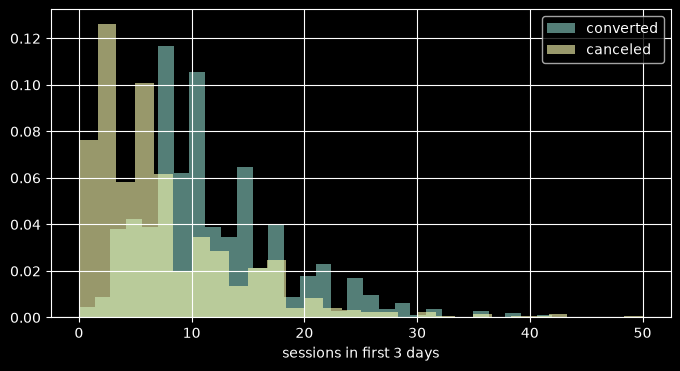

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
df[df.converted == 1]["sessions_3d"].hist(bins=30, alpha=0.6, label="converted", ax=ax, density=True)
df[df.converted == 0]["sessions_3d"].hist(bins=30, alpha=0.6, label="canceled", ax=ax, density=True)
ax.set_xlabel("sessions in first 3 days")
ax.legend()
plt.show()

In [6]:
# heavy day-1 users who then disappear look different from steady users
binge = (df["day1_share"] > 0.6) & (df["sessions_3d"] >= 3)
df.groupby(binge)["converted"].agg(["mean", "count"])

,mean,count
False,0.620601,1165
True,0.239316,351


In [7]:
pd.crosstab(df["country"], df["converted"], normalize="index").round(3)

converted,0,1
country,,
EU,0.507,0.493
India,0.493,0.507
Rest,0.472,0.528
US,0.435,0.565


A few things stand out:

- Converters use the app roughly twice as much in the first 3 days, and they spread that usage across more days.
- The binge pattern is real: users who cram most of their usage into day 1 and then go quiet convert far less than steady users with the same total. Total sessions alone does not tell the whole story.
- Country differences are modest, but they stay in as features anyway.

## Features

The model uses the columns listed in `FEATURES`. The two categorical ones (country, device type) are one-hot encoded inside `build_features`.

In [8]:
print(FEATURES)
print("trials with no sessions in first 3 days:", (df["sessions_3d"] == 0).sum())
df[["sessions_3d", "active_days_3d", "day1_share", "listen_share", "avg_session_minutes"]].describe().round(2)

['sessions_3d', 'active_days_3d', 'day1_share', 'listen_share', 'avg_session_minutes', 'total_minutes_3d', 'country', 'device_type']
trials with no sessions in first 3 days: 38


,sessions_3d,active_days_3d,day1_share,listen_share,avg_session_minutes
count,1516.00,1516.00,1516.00,1516.00,1516.00
mean,9.66,2.46,0.43,0.37,10.31
std,6.94,0.79,0.30,0.26,4.57
min,0.00,0.00,0.00,0.00,0.00
25%,5.00,2.00,0.23,0.18,7.61
50%,8.00,3.00,0.38,0.33,10.00
75%,13.00,3.00,0.67,0.50,12.50
max,50.00,3.00,1.00,1.00,44.00


## Baseline: logistic regression

A quick logistic regression on the same split gives something honest to compare the real model against. This stays in the notebook because it is a comparison, not something production needs.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

train_df, test_df = split_data(df)
X_train, y_train = build_features(train_df)
X_test, y_test = build_features(test_df)

scaler = StandardScaler()
lr = LogisticRegression(max_iter=1000).fit(scaler.fit_transform(X_train), y_train)
lr_probs = lr.predict_proba(scaler.transform(X_test))[:, 1]
print("logistic regression AUC:", round(roc_auc_score(y_test, lr_probs), 4))

logistic regression AUC: 0.8274


## XGBoost

`train_model` fits the model on the training split with the settings in `MODEL_PARAMS`. XGBoost should beat the baseline here, because the binge pattern above is exactly the kind of interaction a linear model cannot capture.

{'n_estimators': 400, 'max_depth': 3, 'learning_rate': 0.05, 'min_child_weight': 8, 'subsample': 0.9, 'colsample_bytree': 0.9, 'eval_metric': 'auc'}


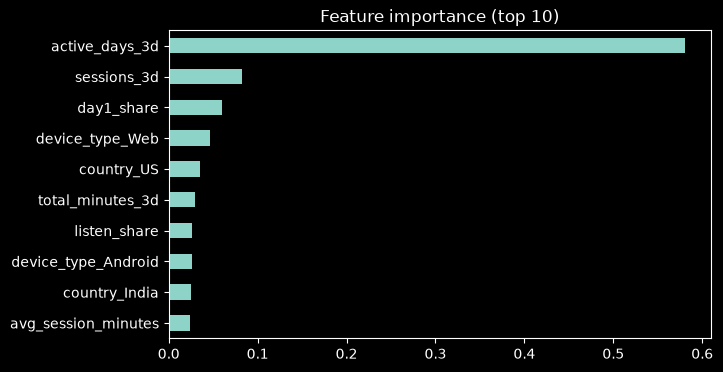

In [10]:
print(MODEL_PARAMS)
model = train_model(df)

importances = pd.Series(model.feature_importances_, index=model.feature_names_in_).sort_values()
importances.tail(10).plot(kind="barh", figsize=(7, 4), title="Feature importance (top 10)")
plt.show()

## Evaluation

`evaluate_held_out` scores the held-out split and returns macro F1, AUC, and the confusion matrix. Macro F1 is the decision metric; AUC is the number to compare against the baseline above.

In [11]:
metrics = evaluate_held_out(model, df)
metrics

{'macro_f1': 0.7934345128291129,
 'auc': 0.8736924539911618,
 'confusion_matrix': [[139, 38], [40, 162]],
 'held_out_rows': 379}

For the growth team, the interesting group is the trials the model says will NOT convert. Those are the ones worth an intervention, such as an onboarding email or a nudge toward audio content, while there is still trial time left.

In [12]:
# who would we intervene on? everyone the model scores below 0.35
probs = predict(model, X_test)
flagged = probs < 0.35
print("flagged for intervention:", flagged.sum(), "of", len(probs))
print("actual conversion rate among flagged:", round(y_test[flagged].mean(), 3))
print("actual conversion rate among the rest:", round(y_test[~flagged].mean(), 3))

flagged for intervention: 150 of 379
actual conversion rate among flagged: 0.173
actual conversion rate among the rest: 0.769


The flagged group converts at a fraction of the rate of everyone else, which is exactly what an intervention list should look like. Where to put the cutoff depends on how many trials the lifecycle team can actually work through per week, so that threshold is their call rather than a modeling decision.

## Next steps

- The production model and its metrics come from `uv run scripts/train.py`, which saves `models/model.pkl` and `models/metrics.json`. This notebook does not save anything.
- The model will need retraining as more trial cohorts mature, especially once the traffic mix from the launch campaign settles.